# Emergency Dispatch & Traffic Physics — Congestion Forecasting

**Practical:** Select 10,000 records, preprocess them, aggregate data by hour, construct time-series sequences, train an LSTM model, evaluate with MAE/RMSE, plot actual versus predicted values, and test on a chronological holdout set.

**Dataset:** [Emergency Dispatch and Traffic Physics Dataset on Kaggle](https://www.kaggle.com/datasets/razinibabadelatif/emergency-dispatch-and-traffic-physics-dataset)

**Selected model:** LSTM (Long Short-Term Memory), implemented with TensorFlow/Keras. It is suitable for sequential observations because it can learn dependencies across prior time steps.

> **Before running:** Add the dataset to this Kaggle Notebook using **Add Input**. The dataset's exact schema can vary; the notebook inspects available files and detects likely timestamp/target columns. Review those choices before continuing. If the target is a categorical congestion level, its labels must have a sensible ordinal mapping for MAE/RMSE.

## 1. Configure the environment

In [1]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import glob
import json
import random
import re
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy
import tensorflow as tf
from tensorflow import keras
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error
import joblib

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("Python environment ready")
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("SciPy:", scipy.__version__)
print("TensorFlow:", tf.__version__)
print("Keras:", keras.__version__ if hasattr(keras, "__version__") else "bundled with TensorFlow")
print("GPU devices:", tf.config.list_physical_devices("GPU"))
try:
    import torch
    print("PyTorch:", torch.__version__, "(installed; this notebook uses TensorFlow/Keras for the LSTM)")
except Exception as e:
    print("PyTorch is not available in this runtime; it is not required for this TensorFlow/Keras implementation.")

Python environment ready
Pandas: 2.3.3
NumPy: 2.1.3
SciPy: 1.16.3
TensorFlow: 2.20.0
Keras: 3.13.2
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]
PyTorch: 2.11.0+cu128 (installed; this notebook uses TensorFlow/Keras for the LSTM)


## 2. Find the dataset files attached to Kaggle

In [2]:
INPUT_ROOT = "/kaggle/input"
all_files = [p for p in glob.glob(f"{INPUT_ROOT}/**/*", recursive=True) if os.path.isfile(p)]

if not all_files:
    raise FileNotFoundError(
        "No input files found. In Kaggle, click Add Input, search for the Emergency Dispatch & Traffic Physics Dataset, and attach it."
    )

file_table = pd.DataFrame({
    "path": all_files,
    "extension": [Path(p).suffix.lower() for p in all_files],
    "size_MB": [round(os.path.getsize(p) / (1024 ** 2), 3) for p in all_files],
}).sort_values("size_MB", ascending=False)
display(file_table)

,path,extension,size_MB
0,/kaggle/input/datasets/rupanarayanan/emergency...,.csv,35.979


## 3. Load a data file and inspect its schema

In [3]:
# Optional: replace None with the exact CSV path shown in the table above if the automatic choice is not the main data file.
DATA_PATH = None

supported = [p for p in all_files if p.lower().endswith((".csv", ".csv.gz", ".parquet", ".json", ".jsonl", ".xlsx"))]
if DATA_PATH is None:
    csv_candidates = [p for p in supported if ".csv" in p.lower()]
    if csv_candidates:
        DATA_PATH = max(csv_candidates, key=os.path.getsize)
    elif supported:
        DATA_PATH = max(supported, key=os.path.getsize)
    else:
        raise FileNotFoundError("No CSV, Parquet, JSON, or Excel files found. Inspect the input files above and adjust the loader.")

print("Chosen file:", DATA_PATH)
if DATA_PATH.lower().endswith((".csv", ".csv.gz")):
    df_raw = pd.read_csv(DATA_PATH, low_memory=False)
elif DATA_PATH.lower().endswith(".parquet"):
    df_raw = pd.read_parquet(DATA_PATH)
elif DATA_PATH.lower().endswith((".json", ".jsonl")):
    df_raw = pd.read_json(DATA_PATH, lines=DATA_PATH.lower().endswith(".jsonl"))
elif DATA_PATH.lower().endswith(".xlsx"):
    df_raw = pd.read_excel(DATA_PATH)
else:
    raise ValueError("Unsupported input file format.")

print("Raw shape:", df_raw.shape)
print("Column names:", list(df_raw.columns))
display(df_raw.head())
display(pd.DataFrame({
    "dtype": df_raw.dtypes.astype(str),
    "missing_count": df_raw.isna().sum(),
    "unique_values": df_raw.nunique(dropna=True),
}).sort_index())

Chosen file: /kaggle/input/datasets/rupanarayanan/emergency-dispatch-and-traffic-physics-dataset/synthetic_traffic_benchmark_200k.csv
Raw shape: (200000, 29)
Column names: ['Record_ID', 'Timestamp', 'Date', 'Hour', 'Month', 'Day_of_Week', 'Time_of_Day', 'Is_Holiday', 'Area_Type', 'Road_Type', 'Intersection_Type', 'Speed_Limit_kmh', 'Weather', 'Road_Condition', 'Visibility_m', 'Congestion_Index', 'Vehicle_Type', 'Driver_Age', 'Driver_Experience_yrs', 'Vehicle_Age_yrs', 'Recorded_Speed_kmh', 'Baseline_Expected_Response_Time_min', 'Accident_Occurred', 'Collision_Type', 'Vehicles_Involved', 'Accident_Severity', 'Dispatch_Priority', 'Actual_Response_Time_min', 'Road_Closure_Duration_min']


,Record_ID,Timestamp,Date,Hour,Month,Day_of_Week,Time_of_Day,Is_Holiday,Area_Type,Road_Type,...,Vehicle_Age_yrs,Recorded_Speed_kmh,Baseline_Expected_Response_Time_min,Accident_Occurred,Collision_Type,Vehicles_Involved,Accident_Severity,Dispatch_Priority,Actual_Response_Time_min,Road_Closure_Duration_min
0,REC_0000000,2024-03-14 17:35:06.841829282,2024-03-14,17,3,Thursday,Evening Peak,0,Urban,Interstate,...,7.2,49.0,6.2,0,NaN,0,No Accident,NaN,0.0,0.0
1,REC_0000001,2023-05-25 08:10:56.398060108,2023-05-25,8,5,Thursday,Morning Peak,0,Suburban,Interstate,...,9.4,70.1,15.0,0,NaN,0,No Accident,NaN,0.0,0.0
2,REC_0000002,2023-11-07 08:25:17.721608262,2023-11-07,8,11,Tuesday,Morning Peak,0,Suburban,Interstate,...,2.9,71.9,14.6,0,NaN,0,No Accident,NaN,0.0,0.0
3,REC_0000003,2024-07-24 09:30:00.947374674,2024-07-24,9,7,Wednesday,Morning Peak,0,Suburban,Collector,...,4.4,58.7,13.2,0,NaN,0,No Accident,NaN,0.0,0.0
4,REC_0000004,2024-04-03 09:34:07.316651267,2024-04-03,9,4,Wednesday,Morning Peak,0,Urban,Local,...,1.8,25.4,7.8,0,NaN,0,No Accident,NaN,0.0,0.0


,dtype,missing_count,unique_values
Accident_Occurred,int64,0,2
Accident_Severity,object,0,5
Actual_Response_Time_min,float64,0,435
Area_Type,object,0,3
Baseline_Expected_Response_Time_min,float64,0,265
Collision_Type,object,191769,4
Congestion_Index,float64,0,1347
Date,object,0,1461
Day_of_Week,object,0,7
Dispatch_Priority,object,191769,3


## 4. Detect timestamp and congestion target columns

The code first makes an educated guess from column names and values. **Check the printed selections against the table from Cell 3.** Set `TIMESTAMP_COL` and `TARGET_COL` explicitly if the guesses are incorrect. Use a timestamp column that records when traffic was observed and a target column that represents congestion (preferably numeric, such as a congestion score, density, flow, speed, or vehicle count selected for the practical).

In [4]:
# Leave as None for automatic detection, or replace with exact column names from df_raw.columns.
TIMESTAMP_COL = None  # Example: "Timestamp"
TARGET_COL = None     # Example: "Congestion_Level"

TIME_NAME_HINTS = ("timestamp", "datetime", "date_time", "event_time", "recorded_at", "date", "time")
TARGET_PRIORITY = [
    "congestion_level", "traffic_congestion", "congestion", "traffic_density",
    "traffic_situation", "traffic_status", "traffic_level", "traffic_flow",
    "traffic_volume", "vehicle_count", "vehicles_count", "occupancy", "density",
    "average_speed", "traffic_speed", "speed", "flow", "traffic"
]


def _parse_time_candidate(series, col_name):
    """Parse text timestamps and common numeric epoch timestamps for schema inspection."""
    s = series
    name = str(col_name).lower()
    if pd.api.types.is_numeric_dtype(s) and any(k in name for k in ("time", "date", "stamp")):
        v = pd.to_numeric(s, errors="coerce")
        med = v.dropna().abs().median() if v.notna().any() else np.nan
        if pd.isna(med):
            return pd.to_datetime(pd.Series([pd.NaT] * len(s)), errors="coerce")
        if med >= 1e17:
            return pd.to_datetime(v, unit="ns", errors="coerce")
        if med >= 1e14:
            return pd.to_datetime(v, unit="us", errors="coerce")
        if med >= 1e11:
            return pd.to_datetime(v, unit="ms", errors="coerce")
        if med >= 1e9:
            return pd.to_datetime(v, unit="s", errors="coerce")
        return pd.to_datetime(s, errors="coerce")
    return pd.to_datetime(s, errors="coerce")


def infer_timestamp_column(frame):
    scored = []
    sample = frame.head(min(500, len(frame)))
    for col in frame.columns:
        name = str(col).lower()
        name_hint = any(k in name for k in TIME_NAME_HINTS)
        # Avoid wasting time parsing obviously unrelated numeric columns.
        if not name_hint and not (pd.api.types.is_datetime64_any_dtype(frame[col])):
            continue
        parsed = _parse_time_candidate(sample[col], col)
        ratio = float(parsed.notna().mean()) if len(parsed) else 0.0
        uniqueness = float(parsed.nunique(dropna=True) / max(parsed.notna().sum(), 1))
        score = ratio + (0.25 if name_hint else 0) + 0.1 * uniqueness
        scored.append((score, ratio, col))
    scored.sort(reverse=True, key=lambda x: x[0])
    return scored


def infer_target_column(frame, excluded=None):
    excluded = set(excluded or [])
    scored = []
    for col in frame.columns:
        if col in excluded:
            continue
        name = str(col).lower().strip().replace("-", "_").replace(" ", "_")
        priority = 0
        for rank, keyword in enumerate(TARGET_PRIORITY):
            if keyword in name:
                priority = len(TARGET_PRIORITY) - rank
                break
        if priority == 0:
            continue
        nonmissing = frame[col].notna().mean()
        unique = frame[col].nunique(dropna=True)
        numeric_share = pd.to_numeric(frame[col], errors="coerce").notna().mean()
        # Prefer a useful target with multiple values; do not choose a near-unique row identifier.
        if unique <= 1 or (unique / max(len(frame), 1) > 0.95 and not any(k in name for k in ("flow", "speed", "density", "congestion"))):
            continue
        score = priority + 2 * numeric_share + nonmissing
        scored.append((score, col, numeric_share, unique))
    scored.sort(reverse=True, key=lambda x: x[0])
    return scored


time_candidates = infer_timestamp_column(df_raw)
target_candidates = infer_target_column(df_raw)
print("Timestamp candidates (score, parse ratio, column):", time_candidates[:8])
print("Target candidates (score, column, numeric share, unique count):", target_candidates[:12])

if TIMESTAMP_COL is None:
    if not time_candidates or time_candidates[0][1] < 0.6:
        raise ValueError("Could not confidently detect a timestamp column. Set TIMESTAMP_COL to the correct column name from Cell 3.")
    TIMESTAMP_COL = time_candidates[0][2]
if TARGET_COL is None:
    if not target_candidates:
        raise ValueError("Could not detect a congestion target column. Set TARGET_COL to the correct column name from Cell 3.")
    TARGET_COL = target_candidates[0][1]

if TIMESTAMP_COL not in df_raw.columns or TARGET_COL not in df_raw.columns:
    raise KeyError(f"Check the configuration: TIMESTAMP_COL={TIMESTAMP_COL!r}, TARGET_COL={TARGET_COL!r} must match actual column names.")
if TIMESTAMP_COL == TARGET_COL:
    raise ValueError("Timestamp and target columns cannot be the same column.")

print("\nSelected timestamp column:", TIMESTAMP_COL)
print("Selected target column:", TARGET_COL)
display(df_raw[[TIMESTAMP_COL, TARGET_COL]].head(10))
print("Target examples:", df_raw[TARGET_COL].dropna().astype(str).unique()[:20])

Timestamp candidates (score, parse ratio, column): [(1.35, 1.0, 'Timestamp'), (1.3328, 1.0, 'Date'), (1.2548, 1.0, 'Baseline_Expected_Response_Time_min'), (1.254, 1.0, 'Actual_Response_Time_min'), (0.25, 0.0, 'Time_of_Day')]
Target candidates (score, column, numeric share, unique count): [(np.float64(19.0), 'Congestion_Index', np.float64(1.0), 1347), (np.float64(6.0), 'Speed_Limit_kmh', np.float64(1.0), 8), (np.float64(6.0), 'Recorded_Speed_kmh', np.float64(1.0), 1986)]

Selected timestamp column: Timestamp
Selected target column: Congestion_Index


,Timestamp,Congestion_Index
0,2024-03-14 17:35:06.841829282,100.0
1,2023-05-25 08:10:56.398060108,100.0
2,2023-11-07 08:25:17.721608262,100.0
3,2024-07-24 09:30:00.947374674,50.0
4,2024-04-03 09:34:07.316651267,78.2
5,2022-12-30 01:16:47.065718381,6.3
6,2025-04-03 09:56:16.240275423,75.4
7,2022-09-14 09:39:13.770496708,47.9
8,2022-05-28 07:28:00.317882302,30.8
9,2025-11-08 19:24:33.007032736,54.8


Target examples: ['100.0' '50.0' '78.2' '6.3' '75.4' '47.9' '30.8' '54.8' '73.1' '95.9'
 '43.2' '75.9' '9.6' '28.9' '2.3' '44.0' '15.1' '72.6' '9.9' '31.4']


## 5. Clean data, select 10,000 records, encode categories, and aggregate by hour

- Records are **sorted by time before selecting up to 10,000 records**. Random sampling would disrupt the sequence and is inappropriate for this forecasting task.
- Missing numerical values are filled using training-period medians; missing categorical values use training-period modes.
- Low-cardinality categorical features are one-hot encoded. ID-like and high-cardinality text columns are excluded to avoid creating thousands of meaningless inputs.
- Observations are aggregated into hourly averages. If the target is a text label such as Low/Medium/High, configure an ordinal mapping below before continuing.

In [5]:
N_RECORDS = 10_000
# Only used if TARGET_COL contains text labels. Map labels in the correct severity order.
# Example: TARGET_MAPPING = {"Low": 0, "Medium": 1, "High": 2}
TARGET_MAPPING = None

work = df_raw.copy()
work["__parsed_timestamp__"] = _parse_time_candidate(work[TIMESTAMP_COL], TIMESTAMP_COL)
work = work.dropna(subset=["__parsed_timestamp__"]).sort_values("__parsed_timestamp__").head(N_RECORDS).copy()
work = work.reset_index(drop=True)
if len(work) < 30:
    raise ValueError(f"Only {len(work)} timestamp-valid records were found. Inspect the timestamp selection and dataset file.")

# Convert the target to numeric or, for labelled congestion levels, to a deliberate ordinal scale.
raw_target = work[TARGET_COL]
target_numeric = pd.to_numeric(raw_target, errors="coerce")
TARGET_IS_CATEGORICAL = target_numeric.notna().mean() < 0.8
TARGET_LABEL_TO_NUMBER = None
TARGET_NUMBER_TO_LABEL = None

if not TARGET_IS_CATEGORICAL:
    work[TARGET_COL] = target_numeric
else:
    if TARGET_MAPPING is not None:
        TARGET_LABEL_TO_NUMBER = {str(k).strip().lower(): float(v) for k, v in TARGET_MAPPING.items()}
    else:
        # Common congestion labels. Review these mappings for the labels shown above.
        ordered_aliases = {
            "very low": 0, "free flow": 0, "freeflow": 0,
            "low": 1, "light": 1, "low congestion": 1,
            "moderate": 2, "medium": 2, "normal": 2, "moderate congestion": 2,
            "high": 3, "heavy": 3, "congested": 3, "high congestion": 3,
            "very high": 4, "severe": 4, "extreme": 5, "jam": 5
        }
        normalized_values = raw_target.dropna().astype(str).str.strip().str.lower().unique()
        if all(v in ordered_aliases for v in normalized_values):
            TARGET_LABEL_TO_NUMBER = {v: float(ordered_aliases[v]) for v in normalized_values}
        else:
            raise ValueError(
                "Target appears categorical, but the labels cannot be safely ordered automatically. "
                f"Observed labels: {list(normalized_values[:30])}. Set TARGET_MAPPING in this cell, "
                "for example {'Low': 0, 'Medium': 1, 'High': 2}, using the actual labels and a meaningful order."
            )
    normalized = raw_target.astype("string").str.strip().str.lower()
    work[TARGET_COL] = normalized.map(TARGET_LABEL_TO_NUMBER)
    unknown_labels = sorted(normalized[work[TARGET_COL].isna()].dropna().unique().tolist())
    if unknown_labels:
        raise ValueError(f"TARGET_MAPPING does not cover these labels: {unknown_labels[:30]}")
    TARGET_NUMBER_TO_LABEL = {int(v): k for k, v in TARGET_LABEL_TO_NUMBER.items()}

# Handle target missing values without looking forward in time: forward-fill, then use a training-prefix median.
target_values = pd.to_numeric(work[TARGET_COL], errors="coerce")
raw_train_cut = max(1, int(0.70 * len(work)))
training_target_median = target_values.iloc[:raw_train_cut].median()
if pd.isna(training_target_median):
    training_target_median = target_values.median()
work[TARGET_COL] = target_values.ffill().fillna(training_target_median)

id_pattern = re.compile(r"(^id$|_id$|^id_|uuid|serial|license|plate|record_id|row_number|^index$|_index$|^index_|row_index)", re.IGNORECASE)
exclude_cols = {TIMESTAMP_COL, "__parsed_timestamp__"}

numeric_features = pd.DataFrame(index=work.index)
categorical_features = []
for col in work.columns:
    if col in exclude_cols:
        continue
    col_name = str(col)
    if col != TARGET_COL and id_pattern.search(col_name):
        continue

    series = work[col]
    numeric_try = pd.to_numeric(series, errors="coerce")
    numeric_share = numeric_try.notna().mean()
    unique_count = series.nunique(dropna=True)

    if col == TARGET_COL:
        numeric_features[col] = pd.to_numeric(series, errors="coerce")
    elif pd.api.types.is_numeric_dtype(series) or (numeric_share >= 0.80 and unique_count > 1):
        # Keep high-cardinality numeric columns: continuous measurements often have mostly unique values.
        # Identifier-like columns are excluded above using their names.
        if unique_count > 1:
            numeric_features[col] = numeric_try
    elif series.dtype == "object" or isinstance(series.dtype, pd.CategoricalDtype) or pd.api.types.is_bool_dtype(series):
        if 2 <= unique_count <= 20:
            categorical_features.append(col)
        elif unique_count > 20:
            print(f"Dropping high-cardinality text feature: {col} ({unique_count} values)")

# Fit simple missing-value replacements on the earliest 70% of the chronologically ordered raw records.
row_cut = max(1, int(0.70 * len(work)))
num_medians = numeric_features.iloc[:row_cut].median(numeric_only=True)
numeric_features = numeric_features.apply(pd.to_numeric, errors="coerce").fillna(num_medians).fillna(0.0)

cat_encoded = pd.DataFrame(index=work.index)
for col in categorical_features:
    train_mode = work[col].iloc[:row_cut].mode(dropna=True)
    fill_value = train_mode.iloc[0] if not train_mode.empty else "Unknown"
    cleaned = work[col].fillna(fill_value).astype(str)
    cat_encoded = pd.concat([cat_encoded, pd.get_dummies(cleaned, prefix=str(col), dtype=float)], axis=1)

# Cyclical calendar features encode time-of-day and day-of-week without false numerical boundaries.
ts = pd.DatetimeIndex(work["__parsed_timestamp__"])
time_features = pd.DataFrame(index=work.index)
time_features["hour_sin"] = np.sin(2 * np.pi * ts.hour / 24)
time_features["hour_cos"] = np.cos(2 * np.pi * ts.hour / 24)
time_features["weekday_sin"] = np.sin(2 * np.pi * ts.dayofweek / 7)
time_features["weekday_cos"] = np.cos(2 * np.pi * ts.dayofweek / 7)
time_features["month_sin"] = np.sin(2 * np.pi * (ts.month - 1) / 12)
time_features["month_cos"] = np.cos(2 * np.pi * (ts.month - 1) / 12)

row_features = pd.concat([numeric_features, cat_encoded, time_features], axis=1)
row_features.index = pd.DatetimeIndex(work["__parsed_timestamp__"], name="timestamp")
row_features = row_features.replace([np.inf, -np.inf], np.nan)

# Aggregate all available road observations to one system-wide hourly series.
hourly = row_features.groupby(row_features.index.floor("h")).mean(numeric_only=True).sort_index()
if hourly.empty or TARGET_COL not in hourly.columns:
    raise ValueError("The target was not retained in hourly aggregation. Recheck TARGET_COL and preprocessing.")

full_hour_index = pd.date_range(hourly.index.min(), hourly.index.max(), freq="h")
hourly = hourly.reindex(full_hour_index)
hourly.index.name = "timestamp"
hourly_train_cut = max(1, int(0.70 * len(hourly)))
hourly_medians = hourly.iloc[:hourly_train_cut].median(numeric_only=True)
# Forward fill only; do not backfill from future observations.
hourly = hourly.ffill().fillna(hourly_medians).fillna(0.0)

# Remove constant inputs but always preserve the target.
constant_cols = [c for c in hourly.columns if c != TARGET_COL and hourly[c].nunique(dropna=True) <= 1]
if constant_cols:
    hourly = hourly.drop(columns=constant_cols)

if hourly[TARGET_COL].nunique(dropna=True) <= 1:
    raise ValueError("The selected target is constant after hourly aggregation. Choose a meaningful congestion target.")
if len(hourly) < 30:
    raise ValueError(
        f"Hourly aggregation produced only {len(hourly)} hours from {len(work)} selected records. "
        "A reliable time-series model needs more distinct hourly observations; check the timestamp column or dataset file."
    )

print(f"Rows selected (maximum 10,000): {len(work):,}")
print(f"Time range: {hourly.index.min()} to {hourly.index.max()}")
print(f"Hourly observations: {len(hourly):,}")
print(f"Model input features: {hourly.shape[1]:,} (target lag is one of the historical inputs)")
print(f"Target: {TARGET_COL}; categorical ordinal target: {TARGET_IS_CATEGORICAL}")
display(hourly.head())
display(hourly.describe().T.head(25))

Path("/kaggle/working").mkdir(parents=True, exist_ok=True)
hourly.to_csv("/kaggle/working/hourly_preprocessed.csv", index_label="timestamp")
print("Saved: /kaggle/working/hourly_preprocessed.csv")

Dropping high-cardinality text feature: Date (74 values)
Rows selected (maximum 10,000): 10,000
Time range: 2022-01-01 00:00:00 to 2022-03-15 16:00:00
Hourly observations: 1,769
Model input features: 71 (target lag is one of the historical inputs)
Target: Congestion_Index; categorical ordinal target: False


,Hour,Month,Is_Holiday,Speed_Limit_kmh,Visibility_m,Congestion_Index,Driver_Age,Driver_Experience_yrs,Vehicle_Age_yrs,Recorded_Speed_kmh,...,Accident_Severity_Severe,Dispatch_Priority_High,Dispatch_Priority_Medium,Dispatch_Priority_Standard,hour_sin,hour_cos,weekday_sin,weekday_cos,month_sin,month_cos
timestamp,,,,,,,,,,,,,,,,,,,,,
2022-01-01 00:00:00,0.0,1.0,0.0,70.000000,9890.950,20.550000,18.500000,2.500000,4.700000,83.000,...,0.0,0.0,0.0,1.0,0.000000,1.000000,-0.974928,-0.222521,0.0,1.0
2022-01-01 01:00:00,0.0,1.0,0.0,70.000000,9890.950,20.550000,18.500000,2.500000,4.700000,83.000,...,0.0,0.0,0.0,1.0,0.000000,1.000000,-0.974928,-0.222521,0.0,1.0
2022-01-01 02:00:00,2.0,1.0,0.0,63.333333,3894.700,26.433333,31.666667,8.866667,12.933333,59.000,...,0.0,0.0,0.0,1.0,0.500000,0.866025,-0.974928,-0.222521,0.0,1.0
2022-01-01 03:00:00,3.0,1.0,0.0,30.000000,1255.800,9.500000,26.000000,10.000000,2.600000,26.400,...,0.0,0.0,0.0,1.0,0.707107,0.707107,-0.974928,-0.222521,0.0,1.0
2022-01-01 04:00:00,4.0,1.0,0.0,45.000000,8149.125,17.550000,33.250000,12.575000,9.550000,38.725,...,0.0,0.0,0.0,1.0,0.866025,0.500000,-0.974928,-0.222521,0.0,1.0


,count,mean,std,min,25%,50%,75%,max
Hour,1769.0,11.538157,6.914297,0.0,6.000000,12.000000,18.000000,23.00
Month,1769.0,1.778971,0.756038,1.0,1.000000,2.000000,2.000000,3.00
Is_Holiday,1769.0,0.027134,0.162520,0.0,0.000000,0.000000,0.000000,1.00
Speed_Limit_kmh,1769.0,57.500604,14.932810,30.0,48.333333,56.666667,65.000000,120.00
Visibility_m,1769.0,4654.200429,2637.524786,161.6,2842.462500,4519.500000,6122.960000,13675.80
Congestion_Index,1769.0,45.081132,24.341520,2.2,21.500000,45.566667,66.414286,100.00
Driver_Age,1769.0,38.337427,7.645912,16.0,34.000000,38.333333,42.250000,79.00
Driver_Experience_yrs,1769.0,10.602557,4.258163,0.0,8.000000,10.330000,12.780000,38.35
Vehicle_Age_yrs,1769.0,6.989608,2.608642,0.4,5.442857,6.661538,8.220000,21.60
Recorded_Speed_kmh,1769.0,48.680999,23.589067,17.4,38.200000,45.242857,54.175000,514.75


Saved: /kaggle/working/hourly_preprocessed.csv


## 6. Visualize the hourly target series

Potential target outliers (|z-score| > 3): 0. Do not remove automatically; traffic peaks may be genuine events.


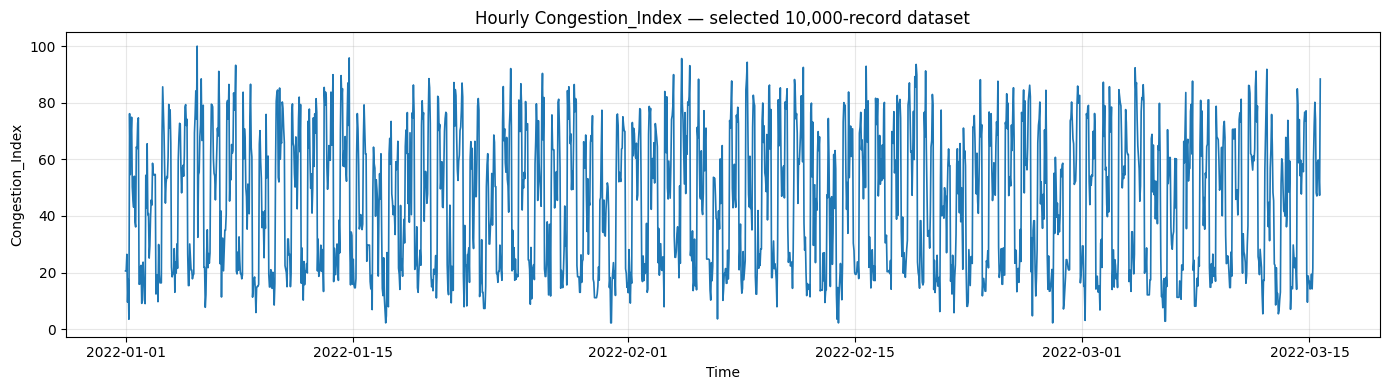

In [6]:
from scipy.stats import zscore
_target_array = hourly[TARGET_COL].to_numpy(dtype=float)
if np.std(_target_array) > 0:
    _z = zscore(_target_array, nan_policy="omit")
    _potential_outliers = np.flatnonzero(np.abs(_z) > 3)
    print(f"Potential target outliers (|z-score| > 3): {len(_potential_outliers)}. Do not remove automatically; traffic peaks may be genuine events.")

plt.figure(figsize=(14, 4))
plt.plot(hourly.index, hourly[TARGET_COL], linewidth=1.2)
plt.title(f"Hourly {TARGET_COL} — selected 10,000-record dataset")
plt.xlabel("Time")
plt.ylabel(TARGET_COL)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("/kaggle/working/hourly_target_series.png", dpi=150, bbox_inches="tight")
plt.show()

## 7. Create sequences and chronological train/validation/test sets

The model uses the previous **up to 24 hours** to predict the next hour. The split is chronological: first 70% for training, next 15% for validation, and final 15% for testing. Random splitting would leak future time patterns into training. The scalers are fitted **only on training hours** to avoid data leakage.

In [7]:
N_HOURS = len(hourly)
LOOKBACK = min(24, max(3, N_HOURS // 10))
train_end = int(0.70 * N_HOURS)
val_end = int(0.85 * N_HOURS)

feature_names = list(hourly.columns)
feature_values = hourly[feature_names].astype("float32").values
target_values_hourly = hourly[TARGET_COL].astype("float32").values.reshape(-1, 1)

x_scaler = MinMaxScaler()
x_scaler.fit(feature_values[:train_end])
features_scaled = x_scaler.transform(feature_values).astype("float32")

y_scaler = MinMaxScaler()
y_scaler.fit(target_values_hourly[:train_end])
target_scaled = y_scaler.transform(target_values_hourly).astype("float32")

X_all, y_all, target_positions = [], [], []
for i in range(LOOKBACK, N_HOURS):
    X_all.append(features_scaled[i - LOOKBACK:i, :])
    y_all.append(target_scaled[i, 0])
    target_positions.append(i)

X_all = np.asarray(X_all, dtype="float32")
y_all = np.asarray(y_all, dtype="float32").reshape(-1, 1)
target_positions = np.asarray(target_positions, dtype=int)

train_mask = target_positions < train_end
val_mask = (target_positions >= train_end) & (target_positions < val_end)
test_mask = target_positions >= val_end

X_train, y_train = X_all[train_mask], y_all[train_mask]
X_val, y_val = X_all[val_mask], y_all[val_mask]
X_test, y_test = X_all[test_mask], y_all[test_mask]
pos_train = target_positions[train_mask]
pos_val = target_positions[val_mask]
pos_test = target_positions[test_mask]

print("Lookback (hours):", LOOKBACK)
print("Input shape:", X_all.shape, "= (sequences, lookback, features)")
print("Train sequences:", len(X_train))
print("Validation sequences:", len(X_val))
print("Test sequences:", len(X_test))
print("Training target period:", hourly.index.min(), "to", hourly.index[train_end - 1])
print("Validation target period:", hourly.index[train_end], "to", hourly.index[val_end - 1])
print("Test target period:", hourly.index[val_end], "to", hourly.index[-1])

if min(len(X_train), len(X_val), len(X_test)) == 0:
    raise ValueError("One time split has zero sequences. The dataset has too few hourly observations for the chosen lookback.")

Lookback (hours): 24
Input shape: (1745, 24, 71) = (sequences, lookback, features)
Train sequences: 1214
Validation sequences: 265
Test sequences: 266
Training target period: 2022-01-01 00:00:00 to 2022-02-21 13:00:00
Validation target period: 2022-02-21 14:00:00 to 2022-03-04 14:00:00
Test target period: 2022-03-04 15:00:00 to 2022-03-15 16:00:00


## 8. Design and train the LSTM model

In [8]:
model = keras.Sequential([
    keras.layers.Input(shape=(LOOKBACK, len(feature_names))),
    keras.layers.LSTM(64, return_sequences=True),
    keras.layers.Dropout(0.20),
    keras.layers.LSTM(32),
    keras.layers.Dense(16, activation="relu"),
    keras.layers.Dense(1, activation="linear")
])

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="mse",
    metrics=["mae"]
)
model.summary()

callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4, min_lr=1e-5)
]

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=50,
    batch_size=32,
    shuffle=False,
    callbacks=callbacks,
    verbose=1
)

I0000 00:00:1792664262.151035      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792664262.155157      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 24, 64)         │        34,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 24, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 47,777 (186.63 KB)

 Trainable params: 47,777 (186.63 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
38/38 ━━━━━━━━━━━━━━━━━━━━ 5s 20ms/step - loss: 0.0586 - mae: 0.2021 - val_loss: 0.0455 - val_mae: 0.1752 - learning_rate: 0.0010
Epoch 2/50
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0378 - mae: 0.1619 - val_loss: 0.0392 - val_mae: 0.1686 - learning_rate: 0.0010
Epoch 3/50
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0375 - mae: 0.1592 - val_loss: 0.0340 - val_mae: 0.1558 - learning_rate: 0.0010
Epoch 4/50
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0288 - mae: 0.1412 - val_loss: 0.0311 - val_mae: 0.1513 - learning_rate: 0.0010
Epoch 5/50
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0262 - mae: 0.1331 - val_loss: 0.0300 - val_mae: 0.1442 - learning_rate: 0.0010
Epoch 6/50
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0220 - mae: 0.1193 - val_loss: 0.0250 - val_mae: 0.1252 - learning_rate: 0.0010
Epoch 7/50
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0173 - mae: 0.1040 - val_loss: 0.0212 - val_mae: 0.1092 - learning_rate: 0.0010
Epoch 8/50
38

## 9. Plot training and validation loss

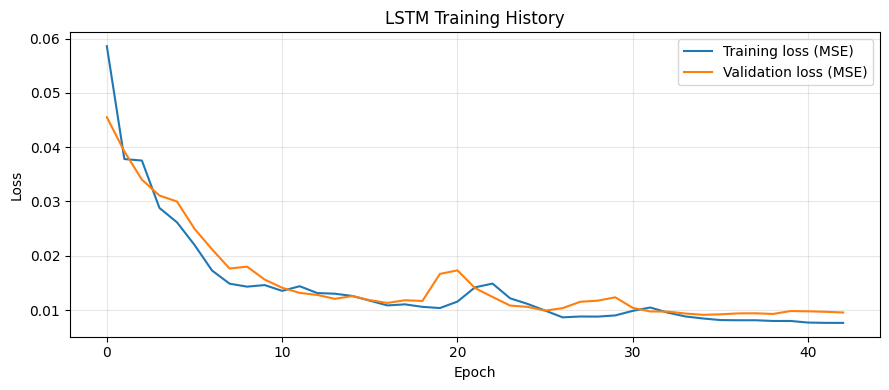

In [9]:
plt.figure(figsize=(9, 4))
plt.plot(history.history["loss"], label="Training loss (MSE)")
plt.plot(history.history["val_loss"], label="Validation loss (MSE)")
plt.title("LSTM Training History")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("/kaggle/working/training_loss.png", dpi=150, bbox_inches="tight")
plt.show()

## 10. Evaluate on unseen chronological test data using MAE and RMSE

In [10]:
y_test_pred_scaled = model.predict(X_test, verbose=0)
y_test_actual = y_scaler.inverse_transform(y_test)
y_test_predicted = y_scaler.inverse_transform(y_test_pred_scaled)

mae = mean_absolute_error(y_test_actual, y_test_predicted)
rmse = float(np.sqrt(mean_squared_error(y_test_actual, y_test_predicted)))
print(f"Test MAE : {mae:.4f} {('(ordinal target units)' if TARGET_IS_CATEGORICAL else '(original target units)')}")
print(f"Test RMSE: {rmse:.4f} {('(ordinal target units)' if TARGET_IS_CATEGORICAL else '(original target units)')}")

# If congestion labels were ordinal-encoded, report a supplementary rounded-label accuracy as well.
if TARGET_IS_CATEGORICAL:
    valid_codes = np.array(sorted(set(TARGET_LABEL_TO_NUMBER.values())), dtype=float)
    rounded_pred = np.array([valid_codes[np.argmin(np.abs(valid_codes - p))] for p in y_test_predicted.ravel()])
    rounded_actual = np.array([valid_codes[np.argmin(np.abs(valid_codes - a))] for a in y_test_actual.ravel()])
    categorical_accuracy = float(np.mean(rounded_pred == rounded_actual))
    print(f"Supplementary ordinal-label accuracy: {categorical_accuracy:.4f}")

metrics = {"test_MAE": float(mae), "test_RMSE": float(rmse), "target_column": str(TARGET_COL),
           "target_is_categorical_ordinal": bool(TARGET_IS_CATEGORICAL), "lookback_hours": int(LOOKBACK),
           "n_raw_records_used": int(len(work)), "n_hourly_observations": int(len(hourly))}
if TARGET_IS_CATEGORICAL:
    metrics["ordinal_label_accuracy"] = float(categorical_accuracy)
print("\nMetrics summary:")
print(json.dumps(metrics, indent=2))

Test MAE : 9.4543 (original target units)
Test RMSE: 12.2268 (original target units)

Metrics summary:
{
  "test_MAE": 9.4542818069458,
  "test_RMSE": 12.226781522598953,
  "target_column": "Congestion_Index",
  "target_is_categorical_ordinal": false,
  "lookback_hours": 24,
  "n_raw_records_used": 10000,
  "n_hourly_observations": 1769
}


## 11. Plot actual versus predicted congestion values

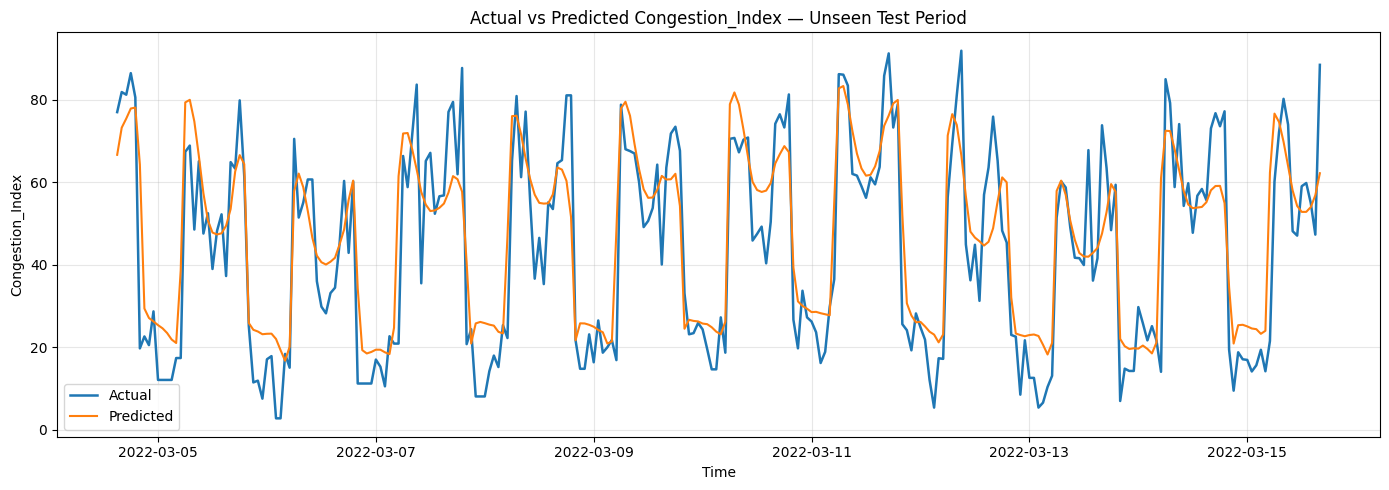

,timestamp,actual,predicted
0,2022-03-04 15:00:00,76.949997,66.610870
1,2022-03-04 16:00:00,81.809998,73.185593
2,2022-03-04 17:00:00,81.166664,75.390404
3,2022-03-04 18:00:00,86.385712,77.823105
4,2022-03-04 19:00:00,80.506668,78.052536
5,2022-03-04 20:00:00,19.740000,64.267670
6,2022-03-04 21:00:00,22.633333,29.390968
7,2022-03-04 22:00:00,20.525000,27.100632
8,2022-03-04 23:00:00,28.700003,26.259399
9,2022-03-05 00:00:00,12.100000,25.367771


Saved: /kaggle/working/test_predictions.csv


In [11]:
test_times = hourly.index[pos_test]
prediction_results = pd.DataFrame({
    "timestamp": test_times,
    "actual": y_test_actual.ravel(),
    "predicted": y_test_predicted.ravel()
})

plt.figure(figsize=(14, 5))
plt.plot(prediction_results["timestamp"], prediction_results["actual"], label="Actual", linewidth=1.8)
plt.plot(prediction_results["timestamp"], prediction_results["predicted"], label="Predicted", linewidth=1.5)
plt.title(f"Actual vs Predicted {TARGET_COL} — Unseen Test Period")
plt.xlabel("Time")
plt.ylabel(TARGET_COL + (" (ordinal code)" if TARGET_IS_CATEGORICAL else ""))
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("/kaggle/working/actual_vs_predicted.png", dpi=150, bbox_inches="tight")
plt.show()

display(prediction_results.head(15))
prediction_results.to_csv("/kaggle/working/test_predictions.csv", index=False)
print("Saved: /kaggle/working/test_predictions.csv")

## 12. Predict congestion for the next hour

In [12]:
latest_sequence = features_scaled[-LOOKBACK:, :][None, :, :]
next_scaled = model.predict(latest_sequence, verbose=0)
next_value = float(y_scaler.inverse_transform(next_scaled)[0, 0])
next_time = hourly.index[-1] + pd.Timedelta(hours=1)

print("Latest observed hour:", hourly.index[-1])
print("Forecast hour       :", next_time)
if TARGET_IS_CATEGORICAL:
    valid_codes = np.array(sorted(set(TARGET_LABEL_TO_NUMBER.values())), dtype=float)
    next_code = float(valid_codes[np.argmin(np.abs(valid_codes - next_value))])
    next_label = TARGET_NUMBER_TO_LABEL.get(int(next_code), f"ordinal level {int(next_code)}")
    print(f"Predicted ordinal score: {next_value:.3f}")
    print(f"Predicted congestion category (nearest ordinal level): {next_label}")
else:
    print(f"Predicted {TARGET_COL}: {next_value:.4f}")

Latest observed hour: 2022-03-15 16:00:00
Forecast hour       : 2022-03-15 17:00:00
Predicted Congestion_Index: 63.0023


## 13. Save the model, scalers, metadata, metrics, and results

In [13]:
OUTPUT_DIR = Path("/kaggle/working")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

model_path = OUTPUT_DIR / "traffic_congestion_lstm.keras"
model.save(model_path)
joblib.dump(x_scaler, OUTPUT_DIR / "feature_scaler.joblib")
joblib.dump(y_scaler, OUTPUT_DIR / "target_scaler.joblib")

metadata = {
    "dataset_path": str(DATA_PATH),
    "timestamp_column": str(TIMESTAMP_COL),
    "target_column": str(TARGET_COL),
    "target_is_categorical_ordinal": bool(TARGET_IS_CATEGORICAL),
    "target_label_to_number": TARGET_LABEL_TO_NUMBER,
    "lookback_hours": int(LOOKBACK),
    "feature_columns": [str(c) for c in feature_names],
    "selected_raw_records": int(len(work)),
    "hourly_observations": int(len(hourly)),
    "train_fraction": 0.70,
    "validation_fraction": 0.15,
    "test_fraction": 0.15,
    "tensorflow_version": str(tf.__version__),
    "random_seed": int(SEED),
    "test_metrics": metrics
}
with open(OUTPUT_DIR / "traffic_forecasting_metadata.json", "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=2, default=str)
with open(OUTPUT_DIR / "test_metrics.json", "w", encoding="utf-8") as f:
    json.dump(metrics, f, indent=2, default=str)

print("Saved artifacts:")
for p in sorted(OUTPUT_DIR.glob("*")):
    if p.is_file():
        print(f"{p.name:40s} {p.stat().st_size / 1024:.1f} KB")

Saved artifacts:
actual_vs_predicted.png                  232.0 KB
feature_scaler.joblib                    2.0 KB
hourly_preprocessed.csv                  976.7 KB
hourly_target_series.png                 274.5 KB
target_scaler.joblib                     0.7 KB
test_metrics.json                        0.2 KB
test_predictions.csv                     9.7 KB
traffic_congestion_lstm.keras            598.7 KB
traffic_forecasting_metadata.json        2.6 KB
training_loss.png                        55.4 KB


## 14. How to run this in Kaggle and upload the results to GitHub

1. Open Kaggle and create a **New Notebook**. Select Python as the language. Under **Add Input**, attach the Emergency Dispatch & Traffic Physics Dataset.
2. In Notebook settings, select a GPU accelerator if available. This small LSTM can also run on CPU, but training may take longer. Internet access is not required when the dataset is attached.
3. Run cells from top to bottom. Inspect the detected timestamp and target columns in **Section 4**. If either is wrong, replace `TIMESTAMP_COL` or `TARGET_COL` with the exact column name printed in Section 3, then rerun from Section 4.
4. If the target contains text categories, set `TARGET_MAPPING` in Section 5 with their correct severity order. Do not assign an arbitrary order to category labels.
5. Review the hourly time-series chart and the test MAE/RMSE. Lower MAE/RMSE indicate smaller prediction errors, but the values must be interpreted in the units of the chosen target. A categorical ordinal target is an approximation, not a continuous physical measurement.
6. Click **Save Version** and enable the option to save the notebook output. Files saved under `/kaggle/working/` appear in the output panel and can be downloaded.
7. Create a GitHub repository, for example `emergency-traffic-congestion-forecasting`. Upload the `.ipynb` notebook, a short `README.md`, `test_metrics.json`, `test_predictions.csv`, and the plots. Upload the `.keras` model only if its file size is reasonable. Do not upload the entire source dataset unless its license explicitly permits redistribution.

### Suggested README summary

**Title:** Emergency Dispatch Traffic Congestion Forecasting using LSTM  
**Objective:** Forecast the next hour's traffic congestion from time-ordered observations to support emergency response and route planning.  
**Pipeline:** Pandas preprocessing → missing-value treatment → categorical encoding → hourly aggregation → MinMax scaling → LSTM → MAE/RMSE evaluation → actual-versus-predicted plot.  
**Model:** Two LSTM layers (64 and 32 units), dropout (0.20), dense layer (16 units), one numeric output; Adam optimizer, MSE loss, early stopping.  
**Validation design:** Chronological 70% train / 15% validation / 15% test; scalers fit only on the training interval.  
**Limitations:** Results depend on the selected target and the dataset's time coverage. Aggregating all available locations by hour forecasts a system-wide hourly average; it does not produce road-specific forecasts unless location is modeled separately.

---

## 15. Assessment rubric checklist (45 marks)

| Rubric component | Evidence in this notebook |
|---|---|
| Framework usage and implementation — 15 | TensorFlow/Keras LSTM, SciPy and scikit-learn ecosystem; versions printed; GPU availability checked. PyTorch is only inspected, not used for training because one framework is sufficient for this implementation. |
| Dataset loading and preprocessing — 5 | Input inspection, up to 10,000 chronological records, missing-value handling, categorical encoding, normalization, hourly aggregation. |
| Model architecture design — 10 | Sequential LSTM architecture with input shape, two recurrent layers, dropout and dense output. |
| Model training and evaluation — 5 | MSE loss, Adam optimizer, early stopping, validation data, MAE/RMSE on the test interval. |
| Result and demonstration — 10 | Training-loss graph, actual-versus-predicted graph, test predictions, next-hour forecast, saved outputs and GitHub publication instructions. |

**Key technical justification:** Traffic data has temporal dependence, so an LSTM is a reasonable baseline. The most likely design failure is selecting a column that is not a meaningful congestion target or using a timestamp that does not represent observation time. Confirm both before interpreting the metrics.